In [2]:
import pandas as pd
import scanpy as sc
import seaborn as sns 
import matplotlib.pyplot as plt

/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
BASE = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/calc_files/MI/clustering_on_MI_genes"

junker_scores = pd.read_csv(f"{BASE}/junker_accuracy_jaccard_scores_20iterations_200genes_fast.csv")
treutlein_scores = pd.read_csv(f"{BASE}/treutlein_accuracy_jaccard_scores_20iterations_200genes_fast.csv")

knoblich_day42_1_scores = pd.read_csv(f"{BASE}/knoblich_day42_1_accuracy_jaccard_scores_20iterations_200genes_fast.csv")
knoblich_day42_2_scores = pd.read_csv(f"{BASE}/knoblich_day42_2_accuracy_jaccard_scores_20iterations_200genes_fast.csv")

knoblich_day16_1_scores = pd.read_csv(f"{BASE}/knoblich_day16_1_accuracy_jaccard_scores_20iterations_200genes_fast.csv")
knoblich_day16_2_scores = pd.read_csv(f"{BASE}/knoblich_day16_2_accuracy_jaccard_scores_20iterations_200genes_fast.csv")

you_stage1_scores = pd.read_csv(f"{BASE}/you_stage1_accuracy_jaccard_scores_20iterations_200genes_fast.csv")
you_stage2_scores = pd.read_csv(f"{BASE}/you_stage2_accuracy_jaccard_scores_20iterations_200genes_fast.csv")
you_stage3_scores = pd.read_csv(f"{BASE}/you_stage3_accuracy_jaccard_scores_20iterations_200genes_fast.csv")
you_stage4_scores = pd.read_csv(f"{BASE}/you_stage4_accuracy_jaccard_scores_20iterations_200genes_fast.csv")

weinreb_scores = pd.read_csv(f"{BASE}/weinreb_accuracy_jaccard_scores_20iterations_200genes_fast.csv")


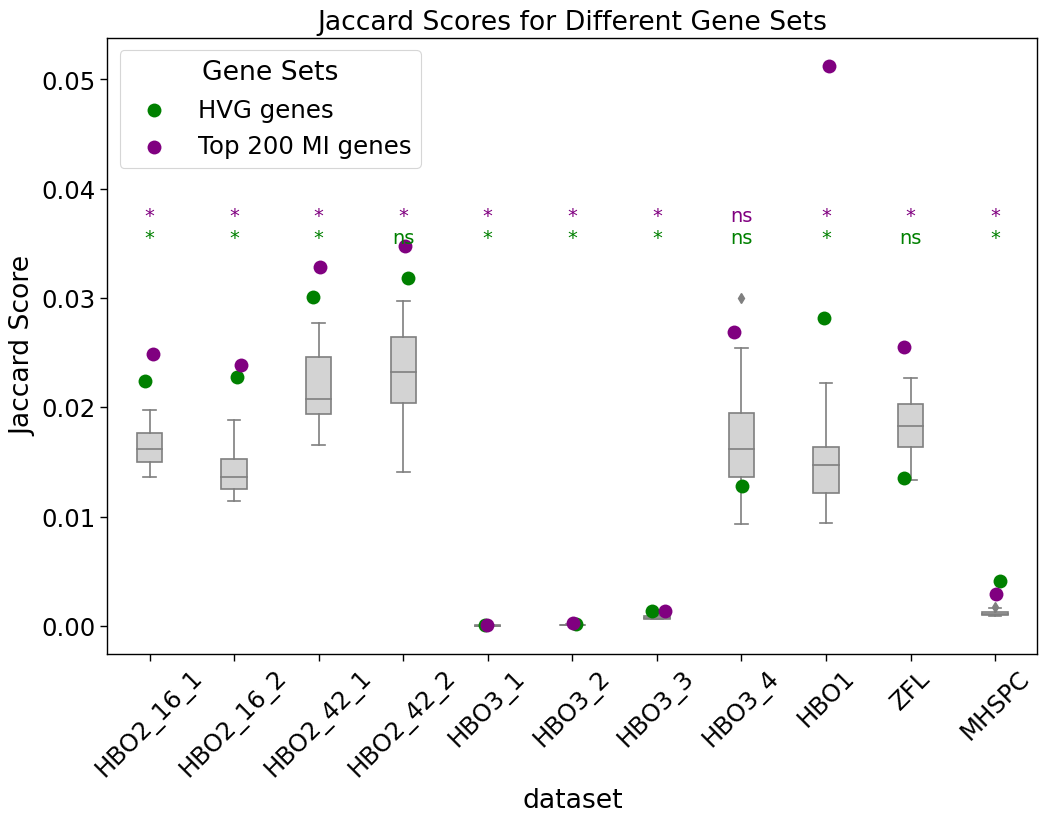

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Add dataset labels
junker_scores['dataset'] = 'ZFL'
knoblich_day42_2_scores['dataset'] = 'HBO2_42_2'
treutlein_scores['dataset'] = 'HBO1'
knoblich_day42_1_scores['dataset'] = 'HBO2_42_1'
knoblich_day16_1_scores['dataset'] = 'HBO2_16_1'
knoblich_day16_2_scores['dataset'] = 'HBO2_16_2'
you_stage1_scores['dataset'] = 'HBO3_1'
you_stage2_scores['dataset'] = 'HBO3_2'
you_stage3_scores['dataset'] = 'HBO3_3'
you_stage4_scores['dataset'] = 'HBO3_4'
weinreb_scores['dataset'] = 'MHSPC'

combined_scores = pd.concat([
    knoblich_day16_1_scores,
    knoblich_day16_2_scores,
    knoblich_day42_1_scores,
    knoblich_day42_2_scores,
    you_stage1_scores,
    you_stage2_scores,
    you_stage3_scores,
    you_stage4_scores,
    treutlein_scores,
    junker_scores,
    weinreb_scores
], ignore_index=True)


def calc_p_value_for_data_point(data, X_0):
    """
    Two-tailed empirical p-value using the sampled null distribution.
    Uses a +1 correction so p is never 0:
        p = (1 + #{|r - mu| >= |x0 - mu|}) / (N + 1)
    """
    r = np.asarray(data, dtype=float)
    mu = float(np.mean(r))
    obs = abs(float(X_0) - mu)
    more_extreme = np.sum(np.abs(r - mu) >= obs)
    return float((1.0 + more_extreme) / (r.size + 1.0))


# Map p-values to stars
def get_pval_stars(p_val):
    if p_val > 5.00e-02:
        return "ns"
    elif 1.00e-02 < p_val <= 5.00e-02:
        return "*"
    elif 1.00e-03 < p_val <= 1.00e-02:
        return "**"
    elif 1.00e-04 < p_val <= 1.00e-03:
        return "***"
    else:
        return "****"

# Visualization
sns.set_context("paper", font_scale=2)
plt.figure(figsize=(12, 8))

x_order = [
    'HBO2_16_1',
    'HBO2_16_2',
    'HBO2_42_1',
    'HBO2_42_2',
    'HBO3_1',
    'HBO3_2',
    'HBO3_3',
    'HBO3_4',
    'HBO1',
    'ZFL',
    'MHSPC'
]

random_genes_scores = combined_scores[combined_scores['gene_set'] == '200 random genes']
sns.boxplot(x="dataset", y='jaccard', data=random_genes_scores, color='lightgray', width=0.3, order = x_order)

# Define gene sets
gene_sets = ['HVG genes', 'Top 200 MI genes']
colors = ['green', 'purple']
y_offsets = {'HVG genes': 0.035, 'Top 200 MI genes': 0.037}
x_position_map = {name: i for i, name in enumerate(x_order)}

for gene_set, color in zip(gene_sets, colors):
    subset = combined_scores[combined_scores['gene_set'] == gene_set]
    sns.stripplot(x='dataset', y='jaccard', data=subset, color=color, label=gene_set, jitter=True, size=10, order = x_order)

    for dataset_name in x_order:
        null_dist = random_genes_scores[random_genes_scores['dataset'] == dataset_name]['jaccard'].values
        data_points = subset[subset['dataset'] == dataset_name]

        x_pos = x_position_map[dataset_name]
        jitter_width = 0.2

        for _, row in data_points.iterrows():
            p_val = calc_p_value_for_data_point(null_dist, row['jaccard'])
            star_label = get_pval_stars(p_val)
            x_jittered = x_pos 
            plt.text(x_jittered, y_offsets[gene_set], star_label, color=color, fontsize=14, ha='center')

# Legend and final layout
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), title='Gene Sets')
plt.xticks(rotation=45)
plt.ylabel('Jaccard Score')
plt.title('Jaccard Scores for Different Gene Sets')
plt.savefig('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/figures/violins_jaccard_scores_with_stars_all_datasets.pdf', bbox_inches='tight')
plt.show()
